<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/11_PlayMind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "gymnasium[classic-control]" moviepy stable-baselines3

In [ ]:
import random, time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch, torch.nn as nn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cpu"                       # tiny MLP: CPU is fine

env = gym.make("CartPole-v1")

def run_random(n_episodes=100):
    rewards = []
    for _ in range(n_episodes):
        env.reset(); total, done = 0, False
        while not done:
            _, r, term, trunc, _ = env.step(env.action_space.sample())
            total += r; done = term or trunc
        rewards.append(total)
    return rewards

rand_rewards = run_random(100)
print(f"Random agent over 100 episodes -> average reward: {np.mean(rand_rewards):.1f}  (max possible 500)")

Random agent over 100 episodes -> average reward: 24.9  (max possible 500)


Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space     : Discrete(2)
Example state    : [ 0.027 -0.006  0.036  0.02 ]


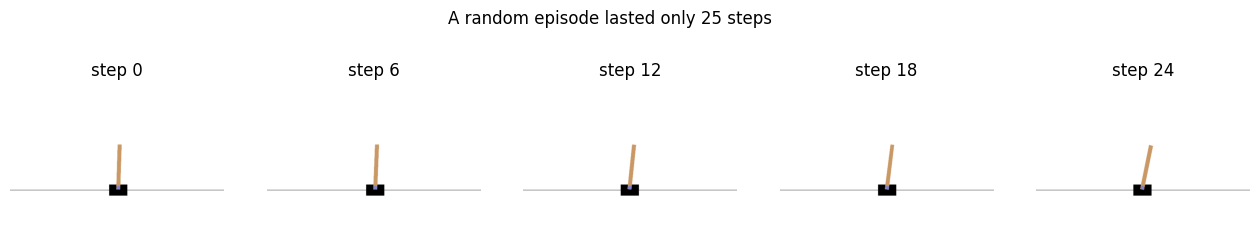

In [ ]:
print("Observation space:", env.observation_space)
print("Action space     :", env.action_space)
state, _ = env.reset(seed=SEED)
print("Example state    :", np.round(state, 3))

# Visualise a random episode (a few frames)
viz_env = gym.make("CartPole-v1", render_mode="rgb_array")
viz_env.reset(seed=SEED); frames, done = [], False
while not done:
    frames.append(viz_env.render())
    _, _, term, trunc, _ = viz_env.step(viz_env.action_space.sample()); done = term or trunc
viz_env.close()

picks = np.linspace(0, len(frames) - 1, 5).astype(int)
fig, ax = plt.subplots(1, 5, figsize=(16, 3))
for a, i in zip(ax, picks):
    a.imshow(frames[i]); a.set_title(f"step {i}"); a.axis("off")
plt.suptitle(f"A random episode lasted only {len(frames)} steps"); plt.show()

In [ ]:
class QNetwork(nn.Module):
    def __init__(self, n_states=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_states, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_actions),
        )
    def forward(self, x):
        return self.net(x)

q_net = QNetwork().to(device)
print(q_net)

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
class ReplayBuffer:
    def __init__(self, capacity=10_000):
        self.buf = deque(maxlen=capacity)
    def push(self, state, action, reward, next_state, done):
        self.buf.append((state, action, reward, next_state, done))
    def sample(self, batch_size=64):
        s, a, r, s2, d = zip(*random.sample(self.buf, batch_size))
        return (torch.FloatTensor(np.array(s)).to(device), torch.LongTensor(a).to(device),
                torch.FloatTensor(r).to(device), torch.FloatTensor(np.array(s2)).to(device),
                torch.FloatTensor(d).to(device))
    def __len__(self):
        return len(self.buf)

In [ ]:
# Hyper-parameters
GAMMA, LR, BATCH = 0.99, 1e-3, 64
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.01, 0.99      # ε multiplied by 0.99 after every episode
TARGET_SYNC, N_EPISODES, SOLVED_AT = 100, 500, 195

q_net      = QNetwork().to(device)
target_net = QNetwork().to(device); target_net.load_state_dict(q_net.state_dict())
optimizer  = torch.optim.Adam(q_net.parameters(), lr=LR)
buffer     = ReplayBuffer(10_000)

def select_action(state, eps):
    if random.random() < eps:
        return env.action_space.sample()                    # explore
    with torch.no_grad():
        return q_net(torch.FloatTensor(state).unsqueeze(0).to(device)).argmax().item()   # exploit

def optimize():
    s, a, r, s2, d = buffer.sample(BATCH)
    q = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)                # Q(s, a)
    with torch.no_grad():
        target = r + GAMMA * target_net(s2).max(1)[0] * (1 - d)       # Bellman / TD target
    loss = nn.functional.mse_loss(q, target)
    optimizer.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(q_net.parameters(), 10.0)               # gradient clipping
    optimizer.step()
    return loss.item()

Episode   1 | reward    10 | 100-ep avg   10.0 | ε 0.990
Episode  25 | reward   114 | 100-ep avg   21.2 | ε 0.778
Episode  50 | reward   149 | 100-ep avg   36.3 | ε 0.605
Episode  75 | reward   135 | 100-ep avg   52.8 | ε 0.471
Episode 100 | reward    23 | 100-ep avg   62.2 | ε 0.366
Episode 125 | reward   197 | 100-ep avg   79.0 | ε 0.285
Episode 150 | reward   117 | 100-ep avg   88.3 | ε 0.221
Episode 175 | reward   186 | 100-ep avg  100.7 | ε 0.172
Episode 200 | reward   168 | 100-ep avg  121.1 | ε 0.134

✅ SOLVED in 223 episodes (100-episode average = 195.6) — 72s


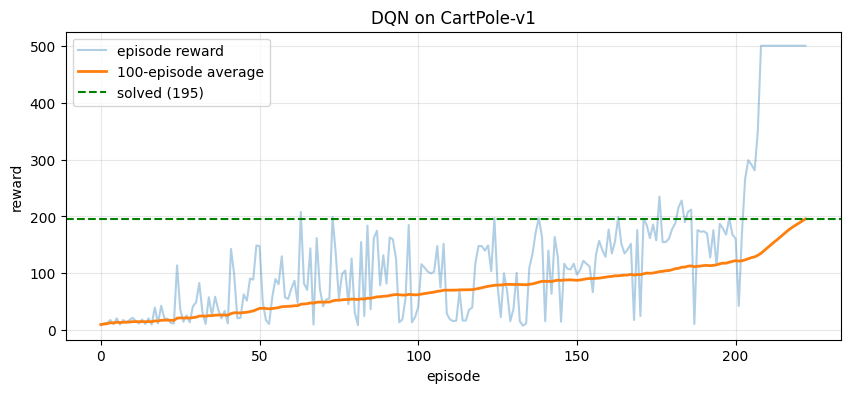

In [ ]:
rewards, step_count, eps, solved_episode = [], 0, EPS_START, None
t0 = time.time()

for ep in range(1, N_EPISODES + 1):
    state, _ = env.reset(seed=SEED + ep)
    total, done = 0.0, False
    while not done:
        action = select_action(state, eps)
        next_state, r, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        buffer.push(state, action, r, next_state, float(terminated))   # only a real failure is "terminal"
        state, total, step_count = next_state, total + r, step_count + 1

        if len(buffer) >= BATCH:
            optimize()
        if step_count % TARGET_SYNC == 0:
            target_net.load_state_dict(q_net.state_dict())

    eps = max(EPS_END, eps * EPS_DECAY)
    rewards.append(total)
    avg100 = np.mean(rewards[-100:])
    if ep % 25 == 0 or ep == 1:
        print(f"Episode {ep:3d} | reward {total:5.0f} | 100-ep avg {avg100:6.1f} | ε {eps:.3f}")
    if len(rewards) >= 100 and avg100 >= SOLVED_AT:
        solved_episode = ep
        print(f"\n✅ SOLVED in {ep} episodes (100-episode average = {avg100:.1f}) — {time.time()-t0:.0f}s")
        break

if solved_episode is None:
    print(f"\nNot solved within {N_EPISODES} episodes (final 100-ep avg {np.mean(rewards[-100:]):.1f}). "
          "DQN can be unstable - re-run the training cells (new seed/weights) or raise N_EPISODES.")

torch.save(q_net.state_dict(), "dqn_cartpole.pt")

# Plot rewards + rolling average
roll = [np.mean(rewards[max(0, i - 99): i + 1]) for i in range(len(rewards))]
plt.figure(figsize=(10, 4))
plt.plot(rewards, alpha=.35, label="episode reward"); plt.plot(roll, lw=2, label="100-episode average")
plt.axhline(SOLVED_AT, ls="--", c="green", label="solved (195)")
plt.xlabel("episode"); plt.ylabel("reward"); plt.legend(); plt.title("DQN on CartPole-v1"); plt.grid(alpha=.3)
plt.show()

In [ ]:
from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display
import glob, shutil, os

# quick greedy evaluation
def greedy_episode(e):
    s, _ = e.reset(); total, done = 0.0, False
    while not done:
        with torch.no_grad():
            a = q_net(torch.FloatTensor(s).unsqueeze(0).to(device)).argmax().item()
        s, r, term, trunc, _ = e.step(a); total += r; done = term or trunc
    return total

eval_scores = [greedy_episode(gym.make("CartPole-v1")) for _ in range(20)]
print(f"Greedy policy over 20 test episodes: mean {np.mean(eval_scores):.1f} | min {np.min(eval_scores):.0f} | max {np.max(eval_scores):.0f}")

n_eps = min(int(input("How many episodes do you want to watch? (1-5): ") or 2), 5)
shutil.rmtree("videos", ignore_errors=True)
rec_env = RecordVideo(gym.make("CartPole-v1", render_mode="rgb_array"), video_folder="videos",
                      episode_trigger=lambda e: True, name_prefix="cartpole")
for i in range(n_eps):
    print(f"Episode {i+1}: reward {greedy_episode(rec_env):.0f}")
rec_env.close()
for v in sorted(glob.glob("videos/*.mp4")):
    display(Video(v, embed=True, width=480))

Greedy policy over 20 test episodes: mean 500.0 | min 500 | max 500
How many episodes do you want to watch? (1-5): 3
Episode 1: reward 500


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Episode 2: reward 500
Episode 3: reward 500


In [ ]:
!pip install -q "gymnasium[atari]" ale-py "stable-baselines3[extra]" huggingface_sb3 shimmy

In [ ]:
import ale_py
try:
    gym.register_envs(ale_py)                         # needed on newer gymnasium versions
except Exception:
    pass
from huggingface_sb3 import load_from_hub
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack, VecVideoRecorder
import shutil
import glob
from IPython.display import Video, display

ENV_ID = "SpaceInvadersNoFrameskip-v4"
ckpt = load_from_hub(repo_id="sb3/dqn-SpaceInvadersNoFrameskip-v4", filename="dqn-SpaceInvadersNoFrameskip-v4.zip")
atari_model = DQN.load(ckpt, custom_objects={
    "learning_rate": 0.0,
    "lr_schedule": lambda _: 0.0,
    "exploration_schedule": lambda _: 0.0,
    "optimize_memory_usage": False
})

atari_env = make_atari_env(ENV_ID, n_envs=1, seed=0, env_kwargs={"render_mode": "rgb_array"})
atari_env = VecFrameStack(atari_env, n_stack=4)                       # the net sees 4 stacked frames
shutil.rmtree("videos_atari", ignore_errors=True)
atari_env = VecVideoRecorder(atari_env, "videos_atari", record_video_trigger=lambda step: step == 0,
                             video_length=1500, name_prefix="spaceinvaders")

obs = atari_env.reset(); score = 0.0
for _ in range(1500):
    action, _ = atari_model.predict(obs, deterministic=True)
    obs, reward, done, info = atari_env.step(action); score += float(reward[0])
atari_env.close()
print("Score during the recording:", score)
display(Video(sorted(glob.glob("videos_atari/*.mp4"))[-1], embed=True, width=480))

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/vec_env/patch_gym.py:95: UserWarning: You loaded a model that was trained using OpenAI Gym. We strongly recommend transitioning to Gymnasium by saving that model again.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/base_class.py:773: UserWarning: You are probably loading a DQN model saved with SB3 < 2.4.0, we truncated the optimizer state so you can save the model again to avoid issues in the future (see https://github.com/DLR-RM/stable-baselines3/pull/1963 for more info). Original error: loaded state dict contains a parameter group that doesn't match the size of optimizer's group 
Note: the model should still work fine, this only a warning.
  warnings.warn(


Saving video to /content/videos_atari/spaceinvaders-step-0-to-step-1500.mp4
Moviepy - Building video /content/videos_atari/spaceinvaders-step-0-to-step-1500.mp4.
Moviepy - Writing video /content/videos_atari/spaceinvaders-step-0-to-step-1500.mp4



Moviepy - Done !
Moviepy - video ready /content/videos_atari/spaceinvaders-step-0-to-step-1500.mp4
Score during the recording: 59.0
